In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('output/paper_results/results_meta_transfer.csv')
df.head()

,seed,num_support,patients,finetune_patients,excluded_patients,auc,skip_base_learner,skip_finetune
0,1,20,[7],[7],"[7, 9, 1, 0, 17]",0.281592,False,False
1,1,20,"[7, 9, 1]","[7, 9, 1]","[7, 9, 1, 0, 17]",0.848946,False,False
2,1,20,"[7, 9, 1, 0, 17]","[7, 9, 1, 0, 17]","[7, 9, 1, 0, 17]",0.870846,False,False
3,1,1,"[7, 9]",[7],"[7, 9, 1, 0, 17]",0.371398,False,False
4,1,1,"[7, 1]",[7],"[7, 9, 1, 0, 17]",0.724593,False,False


In [4]:
import ast
df['num_patients'] = df['patients'].apply(lambda x: len(ast.literal_eval(x)))
df.groupby(['num_patients', 'num_support'])['auc'].mean()

num_patients  num_support
1             1              0.609361
              3              0.660319
              5              0.677069
              10             0.715179
              15             0.705845
              20             0.697258
2             1              0.696291
              3              0.712115
              5              0.727901
              10             0.737764
              15             0.740597
              20             0.744282
3             1              0.657623
              3              0.708055
              5              0.732511
              10             0.744666
              15             0.747021
              20             0.756470
4             1              0.672461
              3              0.702548
              5              0.728123
              10             0.737456
              15             0.741868
              20             0.743498
5             1              0.652397
              3         

In [5]:
df['total_shots_per_class'] = df['num_patients'] * df['num_support']
df.head()

,seed,num_support,patients,finetune_patients,excluded_patients,auc,skip_base_learner,skip_finetune,num_patients,total_shots_per_class
0,1,20,[7],[7],"[7, 9, 1, 0, 17]",0.281592,False,False,1,20
1,1,20,"[7, 9, 1]","[7, 9, 1]","[7, 9, 1, 0, 17]",0.848946,False,False,3,60
2,1,20,"[7, 9, 1, 0, 17]","[7, 9, 1, 0, 17]","[7, 9, 1, 0, 17]",0.870846,False,False,5,100
3,1,1,"[7, 9]",[7],"[7, 9, 1, 0, 17]",0.371398,False,False,2,2
4,1,1,"[7, 1]",[7],"[7, 9, 1, 0, 17]",0.724593,False,False,2,2


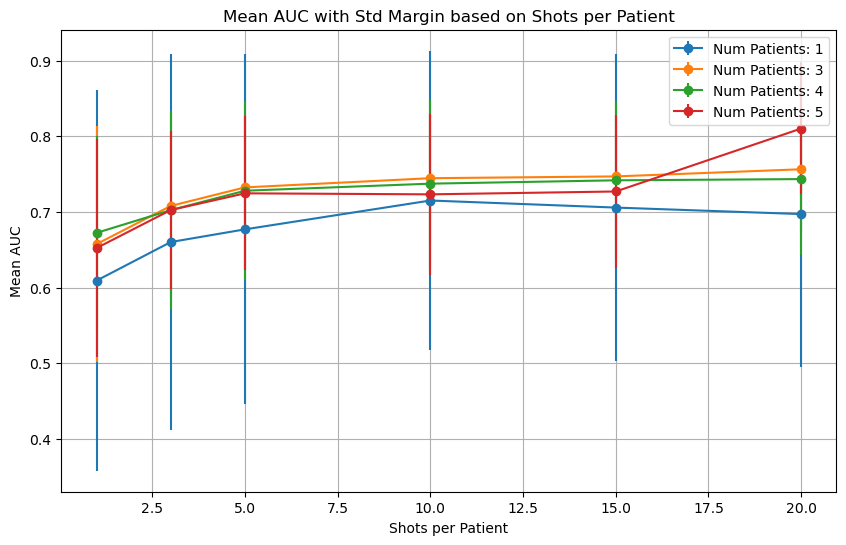

In [6]:

# Group the DataFrame by 'num_patients' and 'total_shots_per_class', and calculate mean and std
grouped = df.groupby(['num_patients', 'num_support'])['auc'].agg(['mean', 'std']).reset_index()
grouped = grouped[grouped['num_patients'] != 2]
# Create a plot
plt.figure(figsize=(10, 6))  # Adjust the figure size as needed

# Iterate through unique 'num_patients' values and plot mean with std margin for each
for num_patients, group in grouped.groupby('num_patients'):
    # plt.plot(group['num_support'], group['mean'], label=f'Num Patients: {num_patients}')
    # plt.fill_between(group['total_shots_per_class'], group['mean'] - group['std'], group['mean'] + group['std'], alpha=0.2)
    plt.errorbar(group['num_support'], group['mean'], yerr=group['std'], label=f'Num Patients: {num_patients}', fmt='-o')
# Add labels and title
plt.xlabel('Shots per Patient')
plt.ylabel('Mean AUC')
plt.title('Mean AUC with Std Margin based on Shots per Patient')
plt.legend()

# Show the plot
plt.grid(True)

In [7]:
df['excluded_patients'].unique()

array(['[7, 9, 1, 0, 17]', '[1, 17, 9, 5, 10]', '[7, 12, 6, 17, 1]',
       '[1, 7, 5, 17, 9]', '[6, 3, 10, 9, 7]', '[10, 0, 12, 1, 6]',
       '[7, 6, 5, 1, 3]', '[17, 0, 1, 12, 10]', '[3, 17, 6, 5, 9]',
       '[6, 12, 0, 7, 1]'], dtype=object)

# Paper Results

In [8]:
df = pd.read_csv('output/paper_results/results_meta_transfer.csv')
df['num_patients'] = df['patients'].apply(lambda x: len(ast.literal_eval(x)))
df['patients'] = df['patients'].apply(lambda x: ast.literal_eval(x))
df['finetune_patients'] = df['finetune_patients'].apply(lambda x: ast.literal_eval(x))
df.sample(n=5)


,seed,num_support,patients,finetune_patients,excluded_patients,auc,skip_base_learner,skip_finetune,num_patients
740,1,20,"[9, 5, 10]","[1, 17, 9]","[1, 17, 9, 5, 10]",0.791447,False,True,3
2860,1,3,"[12, 1, 6]","[10, 0, 12]","[10, 0, 12, 1, 6]",0.727151,False,True,3
4419,99,10,"[17, 1, 10]","[17, 0, 1]","[17, 0, 1, 12, 10]",0.609119,False,True,3
2285,1,3,[9],[6],"[6, 3, 10, 9, 7]",0.205158,False,True,1
1065,99,15,"[1, 9, 5, 10]",[1],"[1, 17, 9, 5, 10]",0.848344,False,False,4


## Compare per number of patients

mean  num_patients
1    0.703452
3    0.867768
5    0.876588
Name: auc, dtype: float64
std  num_patients
1    0.229400
3    0.029879
5    0.026641
Name: auc, dtype: float64


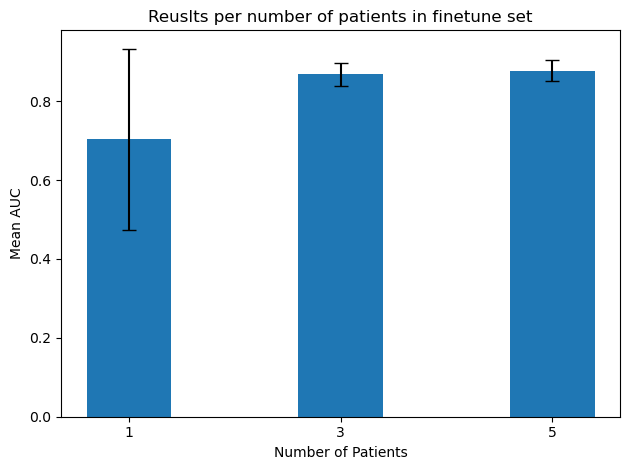

In [9]:
condition = (df['patients'].apply(lambda x: x) == df['finetune_patients']) & (~df['skip_finetune']) & (~df['skip_base_learner'])
df_patient_based = df[condition]
grouped_data = df_patient_based.groupby('num_patients')['auc']

mean_auc = grouped_data.mean()
std_auc = grouped_data.std()
print("mean ", mean_auc)
print("std ", std_auc)
num_patients = mean_auc.index

# Creating the bar plot with error bars
plt.bar(num_patients, mean_auc, yerr=std_auc, capsize=5, align='center')
plt.xlabel('Number of Patients')
plt.ylabel('Mean AUC')
plt.title('Reuslts per number of patients in finetune set')
plt.xticks(num_patients)

plt.tight_layout()
plt.savefig('output/notebook_outputs/per_patient.png')

# mean  num_patients
# 1    0.703452
# 3    0.867768
# 5    0.876588
# Name: auc, dtype: float64
# std  num_patients
# 1    0.229400
# 3    0.029879
# 5    0.026641
# Name: auc, dtype: float64

In [10]:
# Define the output filename
output_csv_name = 'output/paper_results/figure5_epilepsy_raw.csv'

# Save the filtered dataframe to a CSV file
# index=False prevents pandas from adding a new column for the row numbers
# save only the columns of num_patients and auc
df_patient_based[['num_patients', 'auc']].sort_values(by='num_patients').to_csv(output_csv_name, index=False)

print(f"Successfully saved {len(df_patient_based)} contributing rows to {output_csv_name}")

Successfully saved 126 contributing rows to ../output/paper_results/figure5_epilepsy_raw.csv


/tmp/ipykernel_4587/2389539182.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(data_to_plot, labels=labels, showfliers=False, showmeans=True, meanprops=mean_props, whis=(0, 100))


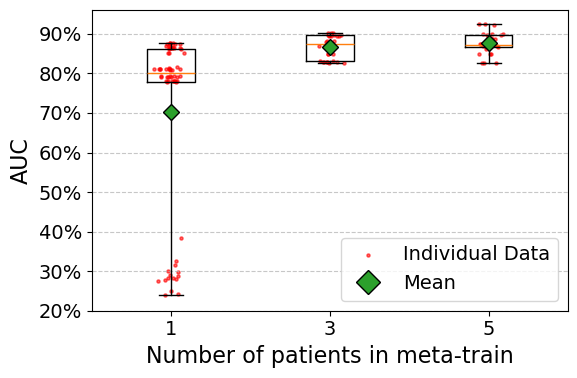

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

# Assuming df_patient_based is already defined from previous steps

# Increase global font size for all plot elements
plt.rcParams.update({'font.size': 14})

plt.figure(figsize=(6, 4))

# Prepare data: Group by 'num_patients' and collect all 'auc' values
grouped = df_patient_based.groupby('num_patients')['auc']
# Multiply by 100 to convert to percentage
data_to_plot = [(group.values[:30]) * 100 for name, group in grouped]
labels = [name for name, group in grouped]

# Define specific properties for the mean marker (Green Diamond)
mean_props = dict(marker='D', markeredgecolor='black', markerfacecolor='#2ca02c', markersize=8)

# Create the boxplot
# showmeans=True enables the mean marker
# whis=(0, 100) ensures whiskers cover the full range (no outliers)
bp = plt.boxplot(data_to_plot, labels=labels, showfliers=False, showmeans=True, meanprops=mean_props, whis=(0, 100))

# Overlay individual data points (jittered scatter plot)
for i, data in enumerate(data_to_plot):
    y = data
    # Create x-coordinates with random jitter
    x = np.random.normal(i + 1, 0.04, size=len(y))
    # Plot points. We only add a label to the first one to avoid duplicate legend entries
    plt.scatter(x, y, alpha=0.6, s=5, color='red', zorder=1, label='Individual Data' if i == 0 else "")

# Add a 'proxy artist' (an empty plot) to create a legend entry for the Mean
plt.plot([], [], marker='D', color='#2ca02c', markeredgecolor='black', linestyle='None', markersize=12, label='Mean')

# Set labels and title with even larger fonts if needed
plt.xlabel('Number of patients in meta-train', fontsize=16)
plt.ylabel('AUC', fontsize=16)
plt.yticks(np.arange(20, 95, 10))
# plt.title('Distribution of AUC per Number of Patients', fontsize=18)

# Add grid
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# Format the Y-axis ticks as percentages
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter())

# Add legend
plt.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.savefig('./per_patient_boxplot_formatted.png')
plt.show()

In [27]:
grouped

## Updating with new shots

0     1
1     3
2     5
3    10
4    15
5    20
Name: num_support, dtype: int64 0    0.696291
1    0.712115
2    0.727901
3    0.737764
4    0.740597
5    0.744282
Name: mean, dtype: float64
6      1
7      3
8      5
9     10
10    15
11    20
Name: num_support, dtype: int64 6     0.677167
7     0.710297
8     0.739375
9     0.750802
10    0.753363
11    0.755525
Name: mean, dtype: float64
12     1
13     3
14     5
15    10
16    15
17    20
Name: num_support, dtype: int64 12    0.672461
13    0.702548
14    0.728123
15    0.737456
16    0.741868
17    0.743498
Name: mean, dtype: float64
18     1
19     3
20     5
21    10
22    15
23    20
Name: num_support, dtype: int64 18    0.652397
19    0.702603
20    0.724673
21    0.723332
22    0.727115
23    0.729298
Name: mean, dtype: float64


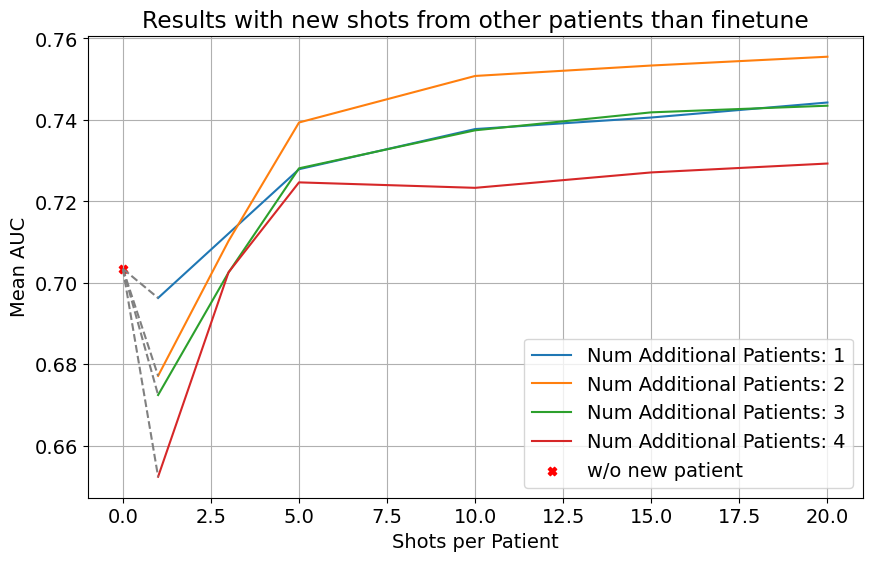

In [13]:
condition = (df['patients'].apply(lambda x: x) != df['finetune_patients']) & (~df['skip_finetune']) & (~df['skip_base_learner'])
df_updating_shots = df[condition]
grouped = df_updating_shots.groupby(['num_patients', 'num_support'])['auc'].agg(['mean', 'std']).reset_index()
# Create a plot
plt.figure(figsize=(10, 6))

# Iterate through unique 'num_patients' values and plot mean with std margin for each
for num_patients, group in grouped.groupby('num_patients'):
    print(group['num_support'], group['mean'])
    plt.plot(group['num_support'], group['mean'], label=f'Num Additional Patients: {num_patients -1}')
    # plt.fill_between(group['to epoch > best_epoch + PATIENCE_STOPPING:
        #     btal_shots_per_class'], group['mean'] - group['std'], group['mean'] + group['std'], alpha=0.2)
    # plt.errorbar(group['num_support'], group['median'], yerr=group['std'], label=f'Num Patients: {num_patients}', fmt='-o')
# Add labels and title
# Add a single point to the plot
additional_point_x = 0
additional_point_y = grouped_data.mean().loc[1]
plt.scatter(additional_point_x, additional_point_y, color='red', marker='X', label='w/o new patient')

# Connect the additional point to all the plots
for num_patients, group in grouped.groupby('num_patients'):
    plt.plot([additional_point_x, group['num_support'].iloc[0]], [additional_point_y, group['mean'].iloc[0]], color='gray', linestyle='dashed')

plt.xlabel('Shots per Patient')
plt.ylabel('Mean AUC')
plt.title('Results with new shots from other patients than finetune')
plt.legend()

# Show the plot
plt.grid(True)
plt.savefig('output/notebook_outputs/new_shot.png')

## Ablation study

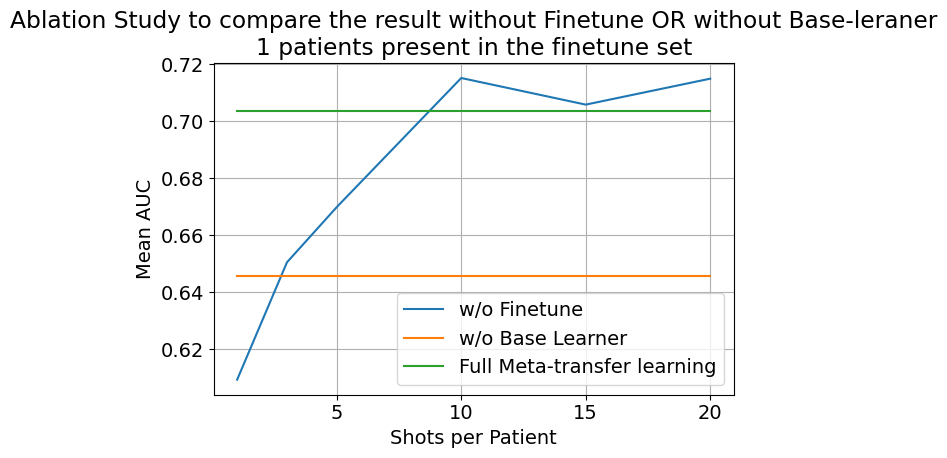

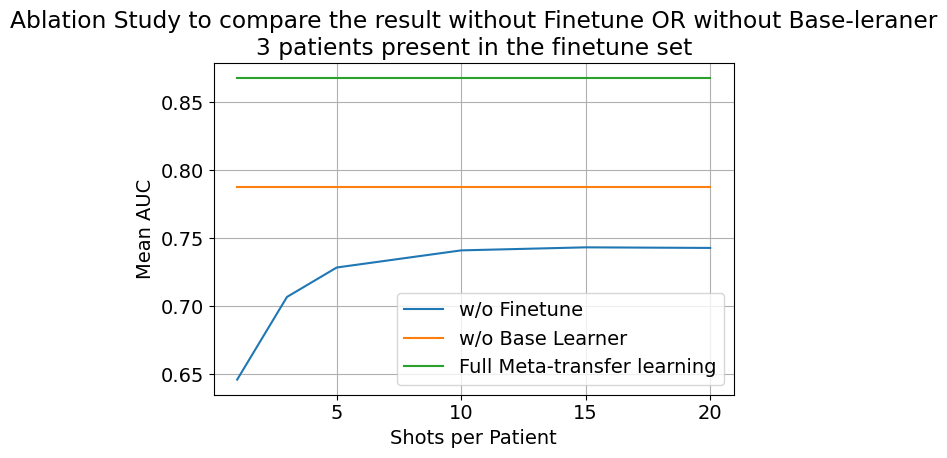

In [14]:
# plt.figure()
df_skip_finetune = df[df['skip_finetune']]
df_skip_base_learner = df[df['skip_base_learner']]
for num_patient_in_FT in [1,3]:
    plt.figure()
    df_skip_finetune[df_skip_finetune['num_patients'] == num_patient_in_FT].groupby('num_support')['auc'].mean().plot(label='w/o Finetune')
    skip_BL_value = df_skip_base_learner[df_skip_base_learner['num_patients'] == num_patient_in_FT].groupby('num_support')['auc'].mean().to_list()
    plt.plot([1, 3, 5, 10, 15, 20], skip_BL_value * 6, label='w/o Base Learner')
    plt.plot([1, 3, 5, 10, 15, 20],[grouped_data.mean().loc[num_patient_in_FT]] * 6, label='Full Meta-transfer learning')

    plt.xlabel('Shots per Patient')
    plt.ylabel('Mean AUC')
    plt.title('Ablation Study to compare the result without Finetune OR without Base-leraner\n{} patients present in the finetune set'.format(num_patient_in_FT))
    plt.legend()

    # Show the plot
    plt.grid(True)
    plt.tight_layout()
    plt.savefig('output/notebook_outputs/Ablation_study_{}.png'.format(num_patient_in_FT))

In [15]:
df_skip_finetune[df_skip_finetune['num_patients'] == num_patient_in_FT].groupby('num_support')['auc'].std()

num_support
1     0.161101
3     0.110510
5     0.084207
10    0.072119
15    0.067456
20    0.068028
Name: auc, dtype: float64

In [16]:
def define_type(row):
    if row['skip_base_learner']:
        return 'Without Base Learner'
    elif row['skip_finetune']:
        # Format num_support as integer for cleaner output (e.g., "5" instead of "5.0")
        shots = int(row['num_support'])
        return f"Without Fine Tune {shots}"
    else:
        return 'Proposed'

df_skip_finetune = df[df['skip_finetune']]
df_skip_base_learner = df[df['skip_base_learner']]
num_patient_in_FT = 3
df_skip_finetune = df_skip_finetune[df_skip_finetune['num_patients'] == num_patient_in_FT]
skip_BL_value = df_skip_base_learner[df_skip_base_learner['num_patients'] == num_patient_in_FT]
proposed_ablation = df_patient_based[df_patient_based['num_patients'] == num_patient_in_FT]

df_ablation_combined = pd.concat([df_skip_finetune, skip_BL_value, proposed_ablation], ignore_index=True)
df_ablation_combined = df_ablation_combined[['auc', 'num_support', 'skip_base_learner','skip_finetune']]


# Apply the function to create the 'type' column
df_ablation_combined['type'] = df_ablation_combined.apply(define_type, axis=1)

df_ablation_combined = df_ablation_combined[['auc', 'type']]

# 4. Save to CSV
output_csv_name = 'output/notebook_outputs/ablation_study_combined.csv'
df_ablation_combined.to_csv(output_csv_name, index=False)

print(f"Successfully saved {len(df_ablation_combined)} rows to {output_csv_name}")


Successfully saved 1860 rows to ./ablation_study_combined.csv


In [17]:
import scipy.stats as stats
data2 = df_skip_base_learner[df_skip_base_learner['num_patients'] == 3]['auc'].to_list()
data1 = df_patient_based[df_patient_based['num_patients'] == 3]['auc'].to_list()
t_stat, p_value = stats.ttest_ind(data1, data2, equal_var=True)  # Assuming unequal variances\
t_stat, p_value

(8.177728157624244, 3.0866341901147937e-11)

In [18]:
data3 = df_skip_finetune[(df_skip_finetune['num_patients'] == 3) & (df_skip_finetune['num_support'] == 20)]['auc'].to_list()
t_stat, p_value = stats.ttest_ind(data1, data3, equal_var=True)  # Assuming unequal variances\
t_stat, p_value

(9.956713971736459, 1.4028794281228903e-20)

# AF results

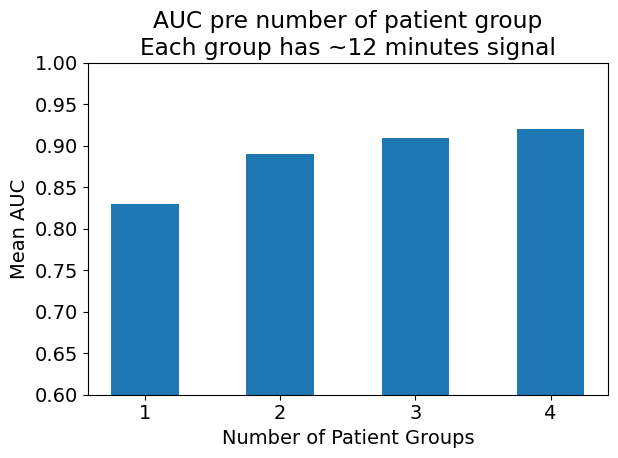

In [19]:

# Creating the bar plot with error bars
plt.bar([1, 2, 3, 4], [0.83, 0.89, 0.91, 0.92], align='center', width=0.5)
plt.xlabel('Number of Patient Groups')
plt.ylabel('Mean AUC')
plt.ylim([0.6, 1.0])
plt.title('AUC pre number of patient group\nEach group has ~12 minutes signal')
plt.xticks([1, 2, 3, 4])

plt.tight_layout()
plt.savefig('./AF_per_patient.png')

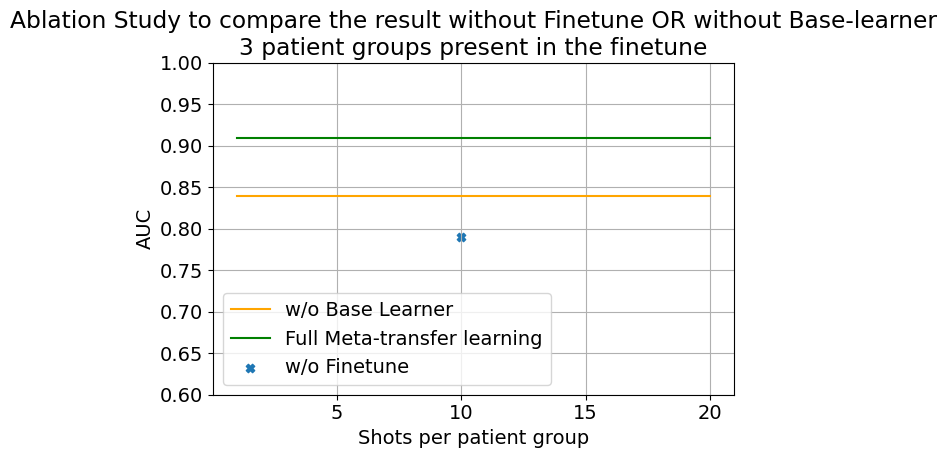

In [20]:
plt.plot([1, 3, 5, 10, 15, 20], [0.84] * 6, label='w/o Base Learner', color='orange')
plt.plot([1, 3, 5, 10, 15, 20],[0.91] * 6, label='Full Meta-transfer learning', color='g')
plt.scatter([10],[0.79], label='w/o Finetune', marker = 'X')
plt.ylim([0.6, 1.0])
plt.xlabel('Shots per patient group')
plt.ylabel('AUC')
plt.title('Ablation Study to compare the result without Finetune OR without Base-learner\n3 patient groups present in the finetune')
plt.legend()
plt.tight_layout()
plt.grid()
plt.savefig('./AF_ablation.png')

## Noise resiliance

/tmp/ipykernel_4587/2318759366.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


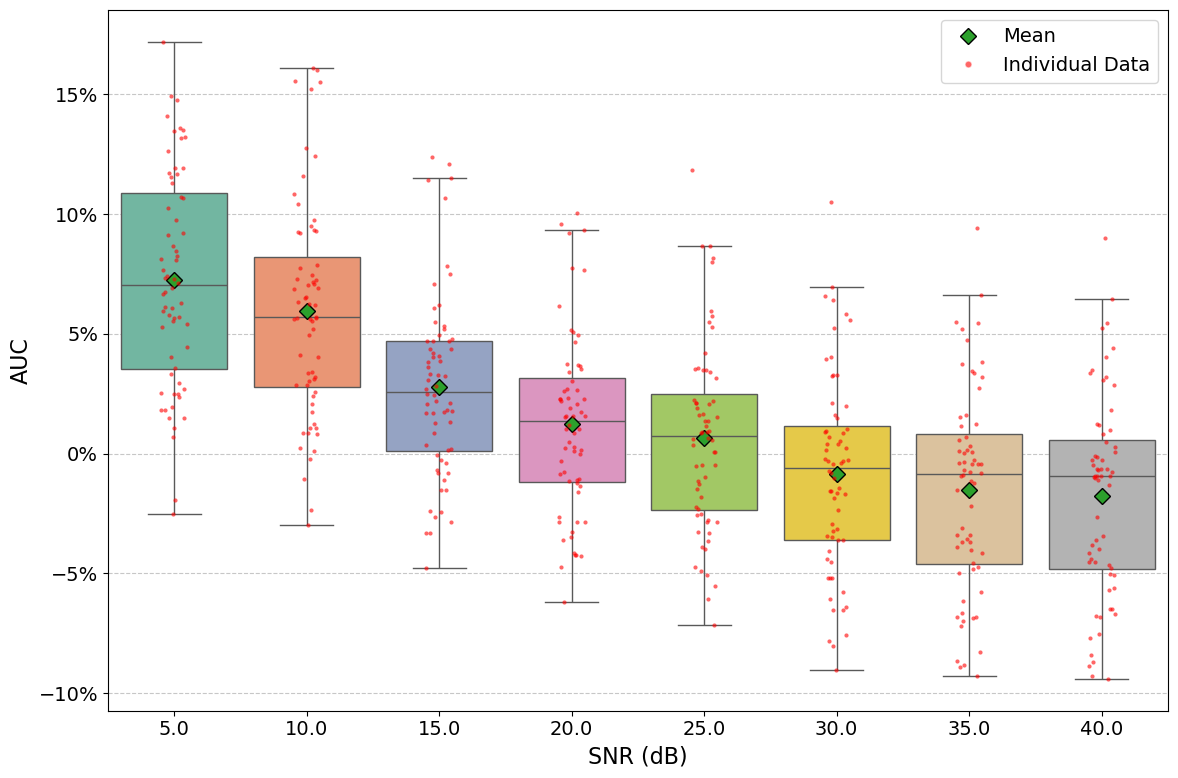

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

# 1. Read the CSV file
# Replace 'your_file_name.csv' with the actual name of your file containing the SNR data
file_path = '../output/paper_results/results_noisy.csv' 
df = pd.read_csv(file_path)

df['auc'] = df['auc'] * 100
df['auc'] = 87.7 - df['auc']

# 2. Filter data
# Remove rows where snr is 0.0001 or 1
df_filtered = df[~df['snr'].isin([0.0001, 1, 1000])].copy()

# 3. Setup the plot
plt.figure(figsize=(12, 8))
# Set consistent global font size
plt.rcParams.update({'font.size': 14})

# Define marker properties for the mean (Green Diamond)
mean_props = dict(marker='D', markeredgecolor='black', markerfacecolor='#2ca02c', markersize=8)

# 4. Create the Box Plot
# showfliers=False prevents outlier points from being plotted by the boxplot itself,
# avoiding duplication with the strip plot points.
ax = sns.boxplot(
    x='snr',
    y='auc',
    data=df_filtered,
    showmeans=True,
    meanprops=mean_props,
    palette="Set2",
    showfliers=False 
)

# 5. Overlay individual data points
# sns.stripplot adds the jittered points on top of the boxes
sns.stripplot(
    x='snr',
    y='auc',
    data=df_filtered,
    color='red',
    size=3,
    jitter=True,
    alpha=0.6,
    zorder=3
)

# 6. Create custom legend
# Define proxy artists for the legend entries
legend_elements = [
    Line2D([0], [0], color='#2ca02c', marker='D', linestyle='None',
           markeredgecolor='black', markersize=8, label='Mean'),
    Line2D([0], [0], marker='.', color='w', label='Individual Data',
           markerfacecolor='red', markersize=10, alpha=0.6)
]

# Add legend to the plot
plt.legend(handles=legend_elements, loc='upper right', frameon=True)

# 7. Formatting
plt.xlabel('SNR (dB)', fontsize=16)
plt.ylabel('AUC', fontsize=16)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

# 8. Save and Show
plt.tight_layout()
plt.savefig('output/notebook_outputs/snr_boxplot_filtered.png', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
# Select only 'snr' and 'auc' columns
output_df = df_filtered[['snr', 'auc']]

# Save to CSV
# index=False ensures the row numbers are not saved as a separate column
output_csv_name = 'output/notebook_outputs/snr_auc_results.csv'
output_df.to_csv(output_csv_name, index=False)

print(f"Successfully saved {len(output_df)} rows to {output_csv_name}")

Successfully saved 512 rows to ./snr_auc_results.csv
